<a href="https://colab.research.google.com/github/padmashree07-sudo/MLA0201-P.PADMASHREE-fundamentals-of-machine-learning/blob/main/EXP_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Dataset:
     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No


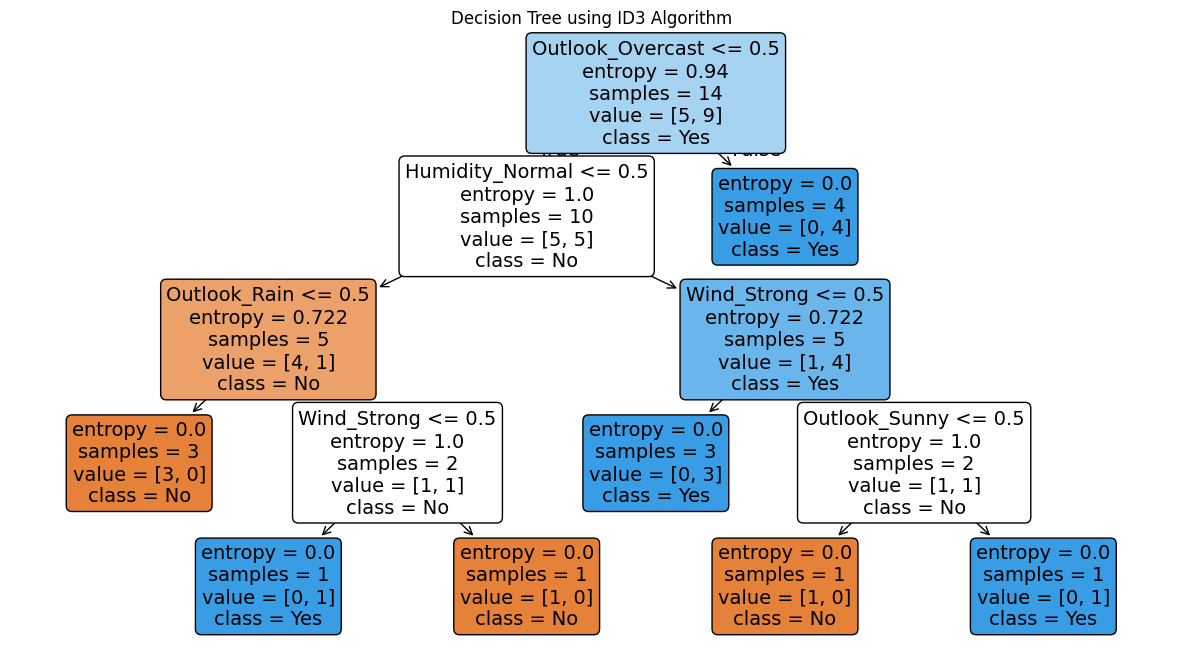


New Sample:
Outlook = Sunny
Temperature = Cool
Humidity = High
Wind = Strong

Predicted Result: No


In [1]:
"""Experiment 3: ID3 decision tree (PlayTennis) with matplotlib tree drawing."""
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# ---------------------------------------
# 1. Create Dataset
# ---------------------------------------

data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain',
                'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain',
                'Sunny', 'Overcast', 'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool',
                    'Cool', 'Cool', 'Mild', 'Cool', 'Mild',
                    'Mild', 'Mild', 'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal',
                 'Normal', 'Normal', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'High'],

    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Strong'],

    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes',
             'No', 'Yes', 'No', 'Yes', 'Yes',
             'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)

print("Training Dataset:")
print(df)


# ---------------------------------------
# 2. Convert Categorical Data to Numbers
# ---------------------------------------

X = pd.get_dummies(df.drop('Play', axis=1))
y = df['Play']


# ---------------------------------------
# 3. Build ID3 Decision Tree
# ---------------------------------------

model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X, y)


# ---------------------------------------
# 4. Display Decision Tree
# ---------------------------------------

plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree using ID3 Algorithm")
plt.show()


# ---------------------------------------
# 5. Predict a New Sample
# ---------------------------------------

new_sample = pd.DataFrame({
    'Outlook': ['Sunny'],
    'Temperature': ['Cool'],
    'Humidity': ['High'],
    'Wind': ['Strong']
})

# Convert new sample in same format as training data
new_sample = pd.get_dummies(new_sample)

# Make sure columns are same as training data
new_sample = new_sample.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(new_sample)

print("\nNew Sample:")
print("Outlook = Sunny")
print("Temperature = Cool")
print("Humidity = High")
print("Wind = Strong")

print("\nPredicted Result:", prediction[0])